In [1]:
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

print("CPU configuration completed")

CPU configuration completed


In [2]:
%pip install networkx matplotlib pandas numpy scipy scikit-learn python-louvain

Note: you may need to restart the kernel to use updated packages.


In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy
import sklearn
import community as community_louvain

print("All libraries imported successfully!")
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NetworkX: 3.4.2
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


DATASET LOADED SUCCESSFULLY
Dataset: Zachary Karate Club
Number of nodes: 34
Number of edges: 78


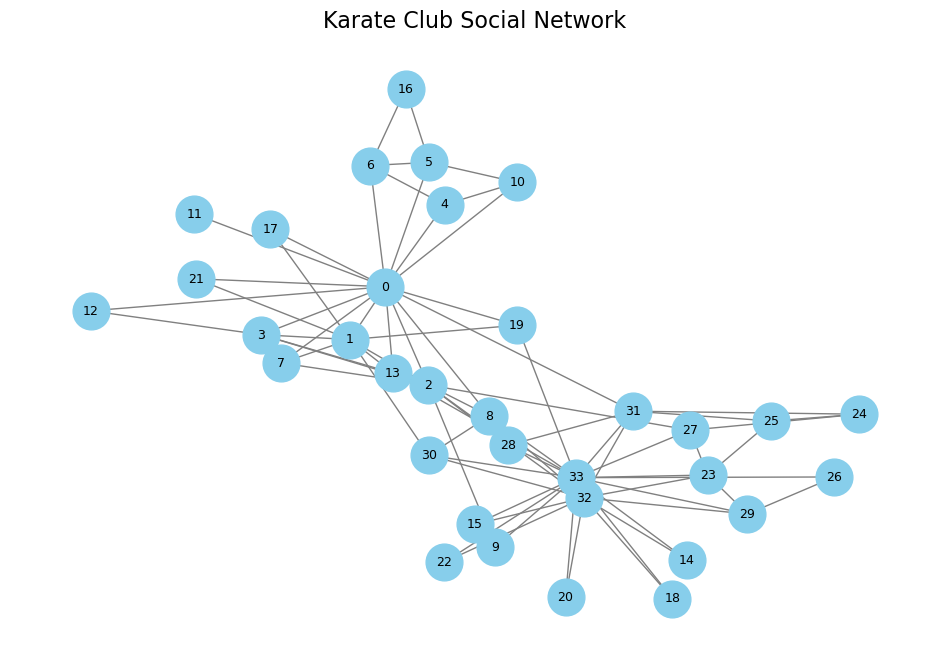

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

print("DATASET LOADED SUCCESSFULLY")
print("Dataset: Zachary Karate Club")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_color="skyblue",
    edge_color="gray",
    node_size=700,
    font_size=9,
    with_labels=True
)

plt.title("Karate Club Social Network", fontsize=16)
plt.axis("off")
plt.show()

In [5]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

G = nx.karate_club_graph()

print("Dataset prepared successfully")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

ground_truth = [
    0 if G.nodes[node]["club"] == "Mr. Hi" else 1
    for node in G.nodes()
]

print("Ground truth communities:", len(set(ground_truth)))

Dataset prepared successfully
Nodes: 34
Edges: 78
Ground truth communities: 2


In [6]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from community import community_louvain
from networkx.algorithms.community import (
    greedy_modularity_communities,
    asyn_lpa_communities,
    girvan_newman
)
from itertools import islice

results = {}

# 1. Louvain
start = time.perf_counter()

partition = community_louvain.best_partition(G, random_state=42)

louvain_communities = [
    {node for node, label in partition.items() if label == community}
    for community in sorted(set(partition.values()))
]

results["Louvain"] = louvain_communities
louvain_time = time.perf_counter() - start

# 2. Greedy Modularity
start = time.perf_counter()

greedy_communities = list(greedy_modularity_communities(G))
results["Greedy Modularity"] = greedy_communities
greedy_time = time.perf_counter() - start

# 3. Label Propagation
start = time.perf_counter()

lpa_communities = list(asyn_lpa_communities(G, seed=42))

results["Label Propagation"] = lpa_communities
lpa_time = time.perf_counter() - start

# 4. Spectral Clustering
start = time.perf_counter()

adjacency = nx.to_numpy_array(G)

spectral = SpectralClustering(
    n_clusters=4,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42,
    n_init=20
)

spectral_labels = spectral.fit_predict(adjacency)

spectral_communities = [
    set(np.where(spectral_labels == label)[0])
    for label in np.unique(spectral_labels)
]

results["Spectral Clustering"] = spectral_communities
spectral_time = time.perf_counter() - start
# 5. Girvan-Newman
start = time.perf_counter()

gn_generator = girvan_newman(G)

gn_communities = list(next(islice(gn_generator, 3, 4)))

results["Girvan-Newman"] = gn_communities
gn_time = time.perf_counter() - start

print("ALL FIVE ALGORITHMS EXECUTED SUCCESSFULLY")

ALL FIVE ALGORITHMS EXECUTED SUCCESSFULLY


In [7]:
execution_times = {
    "Louvain": louvain_time,
    "Greedy Modularity": greedy_time,
    "Label Propagation": lpa_time,
    "Spectral Clustering": spectral_time,
    "Girvan-Newman": gn_time
}

comparison = []

for name, communities in results.items():

    labels = np.zeros(G.number_of_nodes(), dtype=int)

    for community_id, community in enumerate(communities):
        for node in community:
            labels[node] = community_id

    modularity = nx.community.modularity(G, communities)

    nmi = normalized_mutual_info_score(
        ground_truth, labels
    )

    ari = adjusted_rand_score(
        ground_truth, labels
    )

    comparison.append({
        "Algorithm": name,
        "Communities": len(communities),
        "Modularity": round(modularity, 4),
        "NMI": round(nmi, 4),
        "ARI": round(ari, 4),
        "Runtime (seconds)": round(execution_times[name], 6)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="Modularity",
    ascending=False
)

display(comparison_df)

,Algorithm,Communities,Modularity,NMI,ARI,Runtime (seconds)
3,Spectral Clustering,4,0.4449,0.5878,0.4646,0.287888
0,Louvain,4,0.4439,0.6000,0.5089,0.010302
2,Label Propagation,4,0.4366,0.5056,0.4588,0.003594
1,Greedy Modularity,3,0.4110,0.5646,0.5684,0.016771
4,Girvan-Newman,5,0.3850,0.4851,0.3916,0.160593


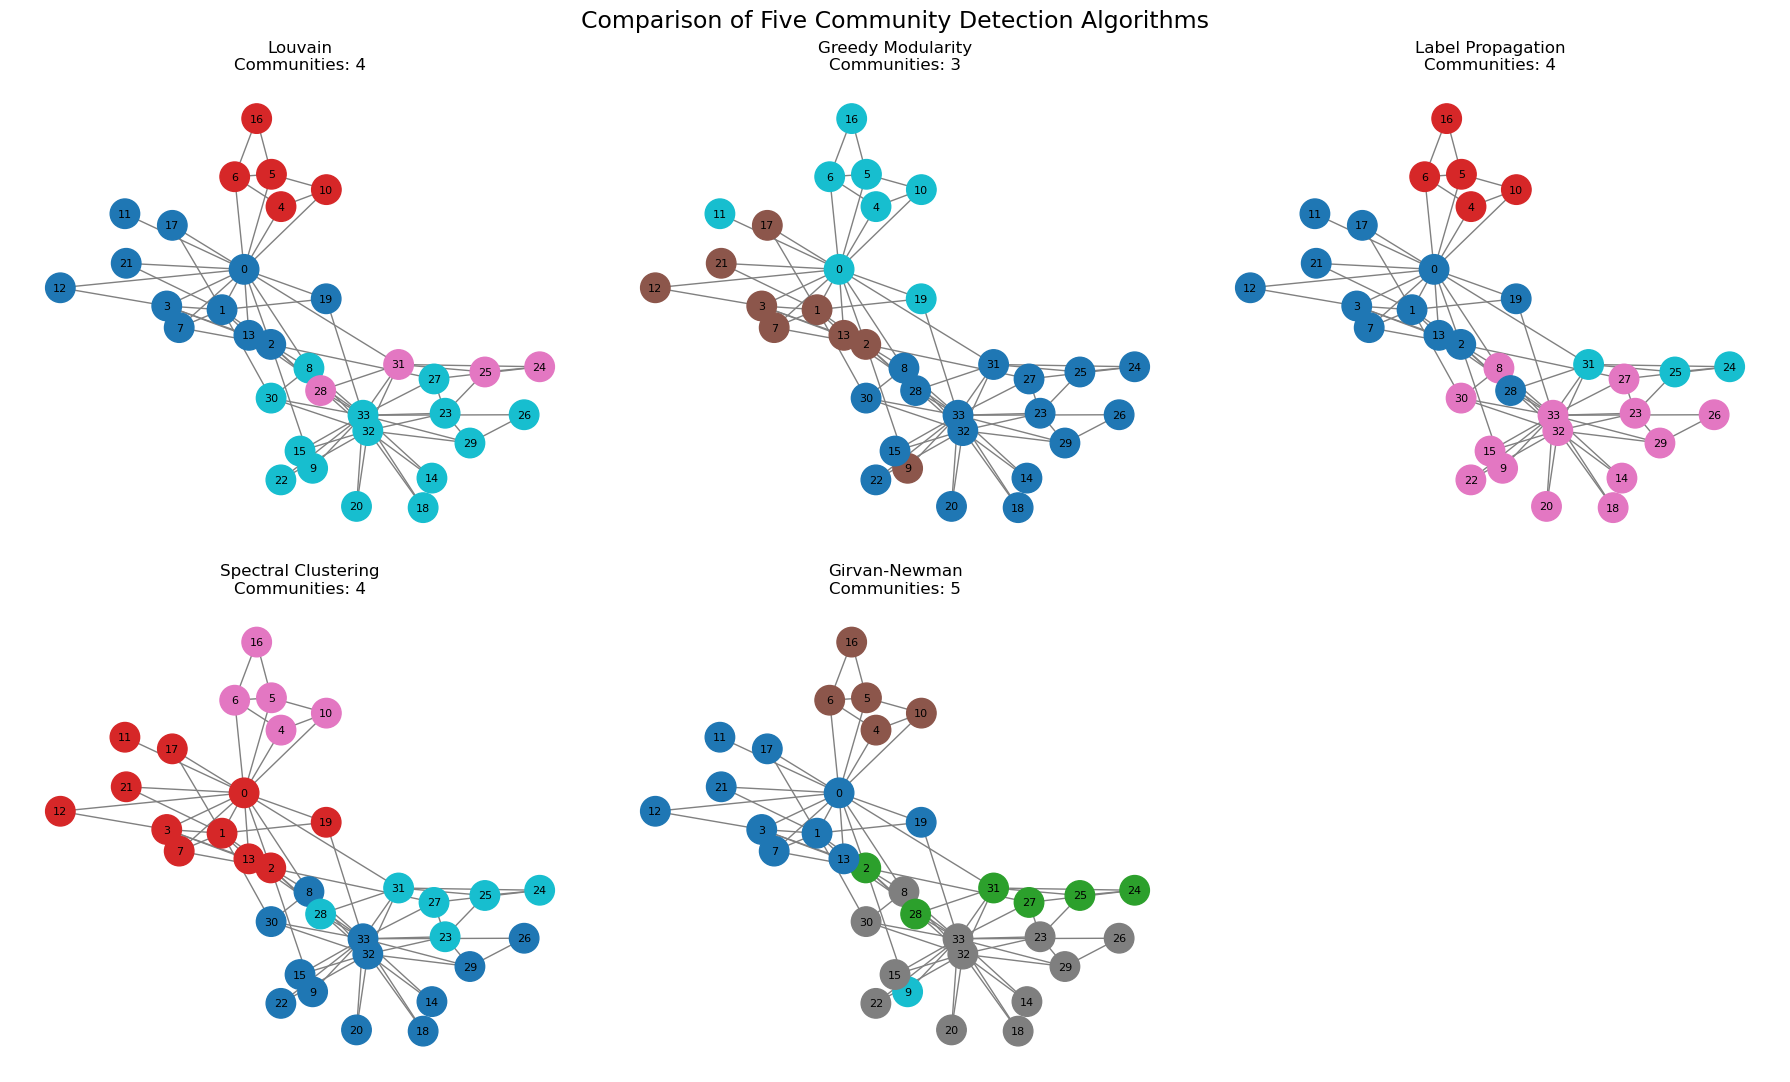

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

pos = nx.spring_layout(G, seed=42)

for ax, (name, communities) in zip(
    axes.flat, results.items()
):

    node_colors = {}

    for community_id, community in enumerate(communities):
        for node in community:
            node_colors[node] = community_id

    colors = [
        node_colors[node]
        for node in G.nodes()
    ]

    nx.draw_networkx(
        G,
        pos,
        ax=ax,
        node_color=colors,
        cmap=plt.cm.tab10,
        node_size=450,
        font_size=8,
        edge_color="gray",
        with_labels=True
    )

    ax.set_title(
        f"{name}\nCommunities: {len(communities)}",
        fontsize=12
    )

    ax.axis("off")

axes.flat[5].axis("off")

plt.suptitle(
    "Comparison of Five Community Detection Algorithms",
    fontsize=17
)

plt.tight_layout()
plt.show()

In [9]:
comparison_df.to_csv(
    "community_algorithm_comparison.csv",
    index=False
)

print("Results saved successfully!")
print("File: community_algorithm_comparison.csv")

Results saved successfully!
File: community_algorithm_comparison.csv


In [10]:
import random
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import SpectralClustering
from sklearn.metrics import normalized_mutual_info_score
from community import community_louvain

from networkx.algorithms.community import (
    greedy_modularity_communities,
    asyn_lpa_communities,
    girvan_newman
)

from itertools import islice

In [11]:
def detect_communities(graph, algorithm, target_k=None):

    if graph.number_of_edges() == 0:
        return [{node} for node in graph.nodes()]

    if algorithm == "Louvain":

        partition = community_louvain.best_partition(
            graph,
            random_state=42
        )

        communities = [
            {node for node, label in partition.items() if label == group}
            for group in sorted(set(partition.values()))
        ]

    elif algorithm == "Greedy Modularity":

        communities = list(
            greedy_modularity_communities(graph)
        )

    elif algorithm == "Label Propagation":

        communities = list(
            asyn_lpa_communities(graph, seed=42)
        )

    elif algorithm == "Spectral Clustering":

        k = target_k or 2
        k = min(k, graph.number_of_nodes())

        adjacency = nx.to_numpy_array(graph)

        model = SpectralClustering(
            n_clusters=k,
            affinity="precomputed",
            assign_labels="kmeans",
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(adjacency)

        communities = [
            set(np.where(labels == label)[0])
            for label in np.unique(labels)
        ]

    elif algorithm == "Girvan-Newman":

        target = target_k or 2

        generator = girvan_newman(graph)

        communities = [
            set(group) for group in nx.connected_components(graph)
        ]

        if len(communities) < target:
            for partition in generator:
                communities = [set(group) for group in partition]

                if len(communities) >= target:
                    break

    else:
        raise ValueError("Unknown algorithm")

    return communities


print("Community detection function created successfully!")

Community detection function created successfully!


In [12]:
algorithms = [
    "Louvain",
    "Greedy Modularity",
    "Label Propagation",
    "Spectral Clustering",
    "Girvan-Newman"
]

removal_levels = [0, 10, 20, 30, 40, 50]

repetitions = 5

robustness_results = []

original_partitions = {}

for algorithm in algorithms:

    original_partitions[algorithm] = detect_communities(
        G,
        algorithm,
        target_k=len(results[algorithm])
    )

    original_labels = np.zeros(G.number_of_nodes(), dtype=int)

    for community_id, community in enumerate(
        original_partitions[algorithm]
    ):
        for node in community:
            original_labels[node] = community_id

    for removal in removal_levels:

        scores = []

        for trial in range(repetitions):

            modified_graph = G.copy()

            random_generator = random.Random(
                42 + trial + removal * 100
            )

            edges = list(modified_graph.edges())

            number_to_remove = int(
                len(edges) * removal / 100
            )

            removed_edges = random_generator.sample(
                edges,
                number_to_remove
            )

            modified_graph.remove_edges_from(removed_edges)

            new_communities = detect_communities(
                modified_graph,
                algorithm,
                target_k=len(original_partitions[algorithm])
            )

            new_labels = np.zeros(
                G.number_of_nodes(),
                dtype=int
            )

            for community_id, community in enumerate(
                new_communities
            ):
                for node in community:
                    new_labels[node] = community_id

            score = normalized_mutual_info_score(
                original_labels,
                new_labels
            )

            scores.append(score)

        robustness_results.append({
            "Algorithm": algorithm,
            "Edges Removed (%)": removal,
            "Average NMI": np.mean(scores),
            "Standard Deviation": np.std(scores)
        })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df.round(4))

print("ROBUSTNESS EXPERIMENT COMPLETED!")

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-p

,Algorithm,Edges Removed (%),Average NMI,Standard Deviation
0,Louvain,0,1.0000,0.0000
1,Louvain,10,0.9347,0.0533
2,Louvain,20,0.7774,0.0749
3,Louvain,30,0.7491,0.0557
4,Louvain,40,0.6121,0.0512
5,Louvain,50,0.6336,0.0719
6,Greedy Modularity,0,1.0000,0.0000
7,Greedy Modularity,10,0.7682,0.0878
8,Greedy Modularity,20,0.6665,0.0516
9,Greedy Modularity,30,0.5800,0.0297


ROBUSTNESS EXPERIMENT COMPLETED!


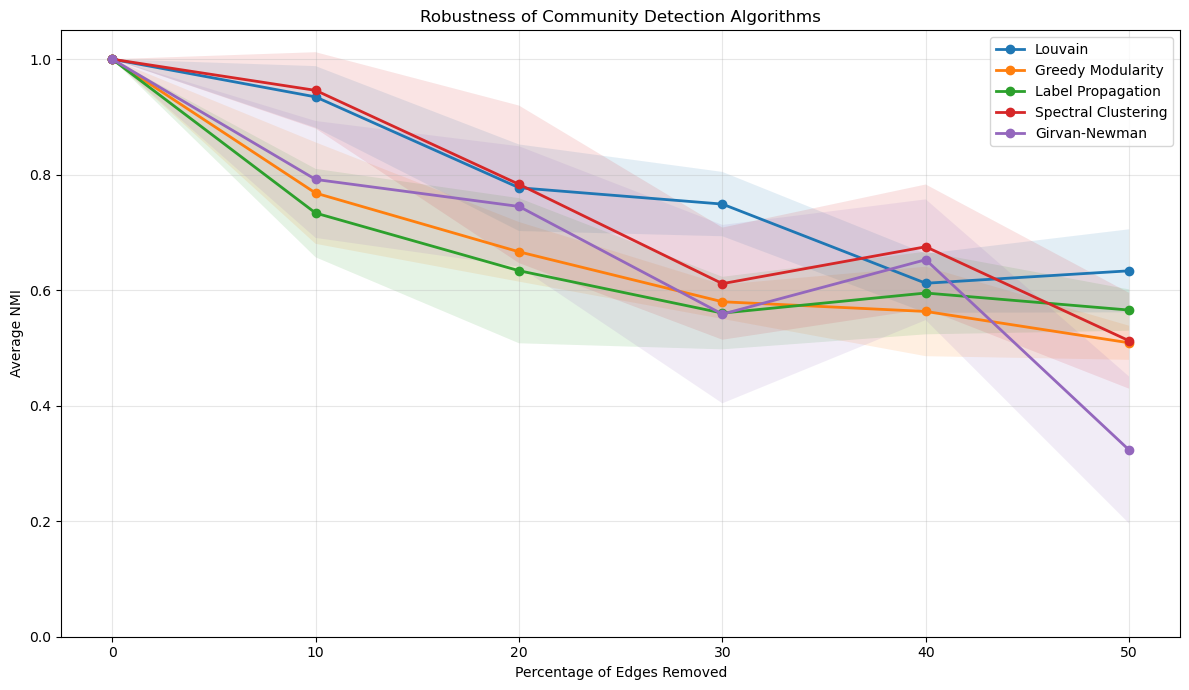

In [13]:
plt.figure(figsize=(12, 7))

for algorithm in algorithms:

    data = robustness_df[
        robustness_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Edges Removed (%)"],
        data["Average NMI"],
        marker="o",
        linewidth=2,
        label=algorithm
    )

    plt.fill_between(
        data["Edges Removed (%)"],
        data["Average NMI"] - data["Standard Deviation"],
        data["Average NMI"] + data["Standard Deviation"],
        alpha=0.12
    )

plt.xlabel("Percentage of Edges Removed")
plt.ylabel("Average NMI")
plt.title("Robustness of Community Detection Algorithms")
plt.xticks(removal_levels)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
robustness_df.to_csv(
    "community_robustness_results.csv",
    index=False
)

print("Robustness results saved successfully!")

Robustness results saved successfully!


In [15]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

communities = results["Louvain"]

node_community = {}

for community_id, community in enumerate(communities):
    for node in community:
        node_community[node] = community_id

print("Louvain communities:", len(communities))
print("Nodes classified:", len(node_community))

Louvain communities: 4
Nodes classified: 34


In [16]:
degree_centrality = nx.degree_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G)

participation = {}
within_degree = {}

for node in G.nodes():

    neighbors = list(G.neighbors(node))
    total_degree = len(neighbors)

    community_counts = {}

    for neighbor in neighbors:
        community_id = node_community[neighbor]

        community_counts[community_id] = (
            community_counts.get(community_id, 0) + 1
        )

    if total_degree == 0:
        participation[node] = 0.0
    else:
        participation[node] = 1 - sum(
            (count / total_degree) ** 2
            for count in community_counts.values()
        )

    within_degree[node] = sum(
        1 for neighbor in neighbors
        if node_community[neighbor] == node_community[node]
    )

within_zscore = {}

for community in communities:

    values = np.array([
        within_degree[node] for node in community
    ], dtype=float)

    mean = values.mean()
    std = values.std()

    for node in community:
        if std == 0:
            within_zscore[node] = 0.0
        else:
            within_zscore[node] = (
                within_degree[node] - mean
            ) / std

print("Node importance metrics calculated successfully!")

Node importance metrics calculated successfully!


In [17]:
node_analysis = pd.DataFrame({
    "Node": list(G.nodes()),
    "Community": [node_community[n] for n in G.nodes()],
    "Degree": [G.degree(n) for n in G.nodes()],
    "Degree Centrality": [degree_centrality[n] for n in G.nodes()],
    "Betweenness": [betweenness_centrality[n] for n in G.nodes()],
    "Within Community Z-score": [within_zscore[n] for n in G.nodes()],
    "Participation Coefficient": [participation[n] for n in G.nodes()]
})

node_analysis = node_analysis.round(4)

display(
    node_analysis.sort_values(
        by="Participation Coefficient",
        ascending=False
    ).head(15)
)

,Node,Community,Degree,Degree Centrality,Betweenness,Within Community Z-score,Participation Coefficient
28,28,2,3,0.0909,0.0018,-1.4142,0.6667
27,27,3,4,0.1212,0.0223,-0.5154,0.6250
31,31,2,6,0.1818,0.1383,1.4142,0.6111
2,2,0,10,0.3030,0.1437,0.3003,0.5800
0,0,0,16,0.4848,0.4376,2.1357,0.5391
9,9,3,2,0.0606,0.0008,-0.8161,0.5000
8,8,3,5,0.1515,0.0559,-0.2148,0.4800
19,19,0,3,0.0909,0.0325,-0.8009,0.4444
10,10,1,3,0.0909,0.0006,-0.8165,0.4444
4,4,1,3,0.0909,0.0006,-0.8165,0.4444


In [18]:
def classify_node(row):

    is_hub = row["Within Community Z-score"] >= 2.0
    is_bridge = row["Participation Coefficient"] >= 0.5

    if is_hub and is_bridge:
        return "Connector Hub"

    elif is_hub:
        return "Community Hub"

    elif is_bridge:
        return "Bridge Node"

    return "Regular Node"


node_analysis["Node Role"] = node_analysis.apply(
    classify_node,
    axis=1
)

display(
    node_analysis.sort_values(
        by="Betweenness",
        ascending=False
    ).head(15)
)

print("\nNODE ROLE SUMMARY")
print(node_analysis["Node Role"].value_counts())

,Node,Community,Degree,Degree Centrality,Betweenness,Within Community Z-score,Participation Coefficient,Node Role
0,0,0,16,0.4848,0.4376,2.1357,0.5391,Connector Hub
33,33,3,17,0.5152,0.3041,2.7920,0.3875,Community Hub
32,32,3,12,0.3636,0.1452,1.8900,0.2917,Regular Node
2,2,0,10,0.3030,0.1437,0.3003,0.5800,Bridge Node
31,31,2,6,0.1818,0.1383,1.4142,0.6111,Bridge Node
8,8,3,5,0.1515,0.0559,-0.2148,0.4800,Regular Node
1,1,0,9,0.2727,0.0539,1.4016,0.1975,Regular Node
13,13,0,5,0.1515,0.0459,-0.0667,0.3200,Regular Node
19,19,0,3,0.0909,0.0325,-0.8009,0.4444,Regular Node
6,6,1,4,0.1212,0.0300,1.2247,0.3750,Regular Node



NODE ROLE SUMMARY
Node Role
Regular Node     27
Bridge Node       5
Connector Hub     1
Community Hub     1
Name: count, dtype: int64


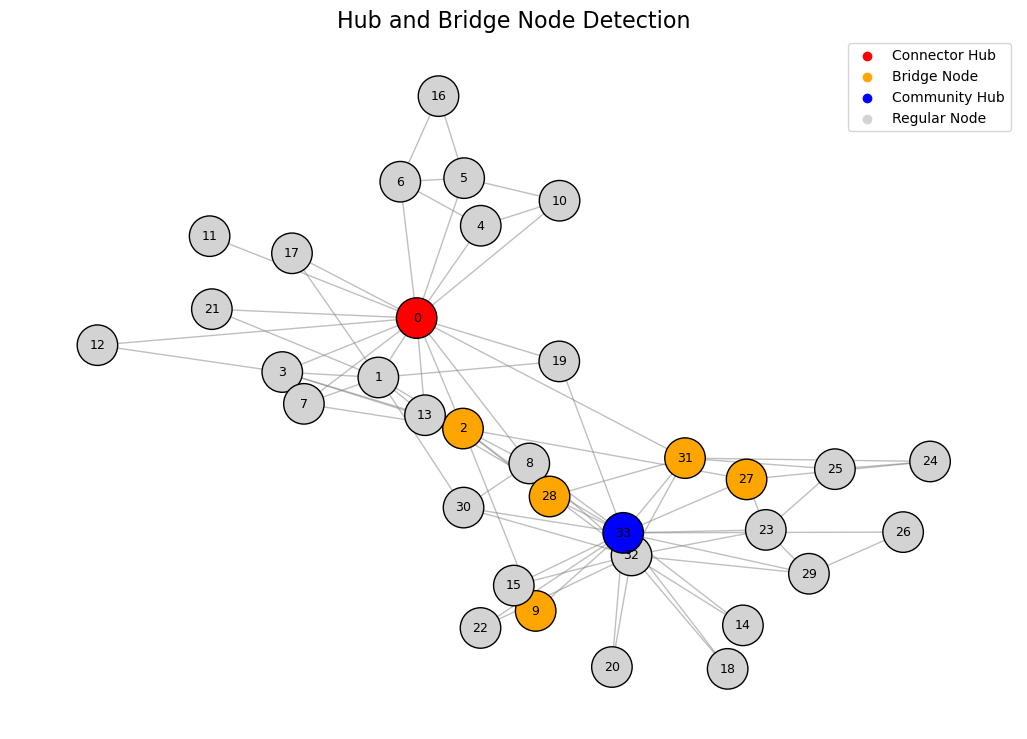

In [19]:
role_colors = {
    "Connector Hub": "red",
    "Bridge Node": "orange",
    "Community Hub": "blue",
    "Regular Node": "lightgray"
}

node_colors = [
    role_colors[node_analysis.loc[
        node_analysis["Node"] == node,
        "Node Role"
    ].iloc[0]]
    for node in G.nodes()
]

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(13, 9))

nx.draw_networkx_edges(
    G, pos,
    edge_color="gray",
    alpha=0.5
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=850,
    edgecolors="black"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9
)

plt.title(
    "Hub and Bridge Node Detection",
    fontsize=16
)

plt.axis("off")

for role, color in role_colors.items():
    plt.scatter([], [], c=color, label=role)

plt.legend()
plt.show()

In [20]:
node_analysis.to_csv(
    "hub_bridge_analysis.csv",
    index=False
)

print("Node analysis saved successfully!")
print("File: hub_bridge_analysis.csv")

Node analysis saved successfully!
File: hub_bridge_analysis.csv


In [21]:
import time
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

network_sizes = [200, 500, 1000, 2000]

scalability_results = []

for size in network_sizes:

    graph = nx.planted_partition_graph(
        l=4,
        k=size // 4,
        p_in=0.08,
        p_out=0.002,
        seed=42
    )

    print(
        f"Generated graph: {graph.number_of_nodes()} nodes, "
        f"{graph.number_of_edges()} edges"
    )

Generated graph: 200 nodes, 395 edges
Generated graph: 500 nodes, 2620 edges
Generated graph: 1000 nodes, 10690 edges
Generated graph: 2000 nodes, 43005 edges


In [22]:
for size in network_sizes:

    graph = nx.planted_partition_graph(
        l=4,
        k=size // 4,
        p_in=0.08,
        p_out=0.002,
        seed=42
    )

    for algorithm in algorithms:

        if algorithm == "Girvan-Newman":
            print(f"Skipping {algorithm} at {size} nodes: expensive algorithm")
            continue

        start = time.perf_counter()

        detected = detect_communities(
            graph,
            algorithm,
            target_k=4
        )

        elapsed = time.perf_counter() - start

        scalability_results.append({
            "Nodes": size,
            "Algorithm": algorithm,
            "Runtime (seconds)": elapsed,
            "Communities": len(detected)
        })

scalability_df = pd.DataFrame(scalability_results)

display(scalability_df.round(4))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Skipping Girvan-Newman at 200 nodes: expensive algorithm
Skipping Girvan-Newman at 500 nodes: expensive algorithm
Skipping Girvan-Newman at 1000 nodes: expensive algorithm
Skipping Girvan-Newman at 2000 nodes: expensive algorithm


,Nodes,Algorithm,Runtime (seconds),Communities
0,200,Louvain,0.0576,5
1,200,Greedy Modularity,0.1313,6
2,200,Label Propagation,0.0103,59
3,200,Spectral Clustering,0.1534,4
4,500,Louvain,0.2897,4
5,500,Greedy Modularity,1.5001,4
6,500,Label Propagation,0.0674,4
7,500,Spectral Clustering,0.1203,4
8,1000,Louvain,0.7312,4
9,1000,Greedy Modularity,8.9238,4


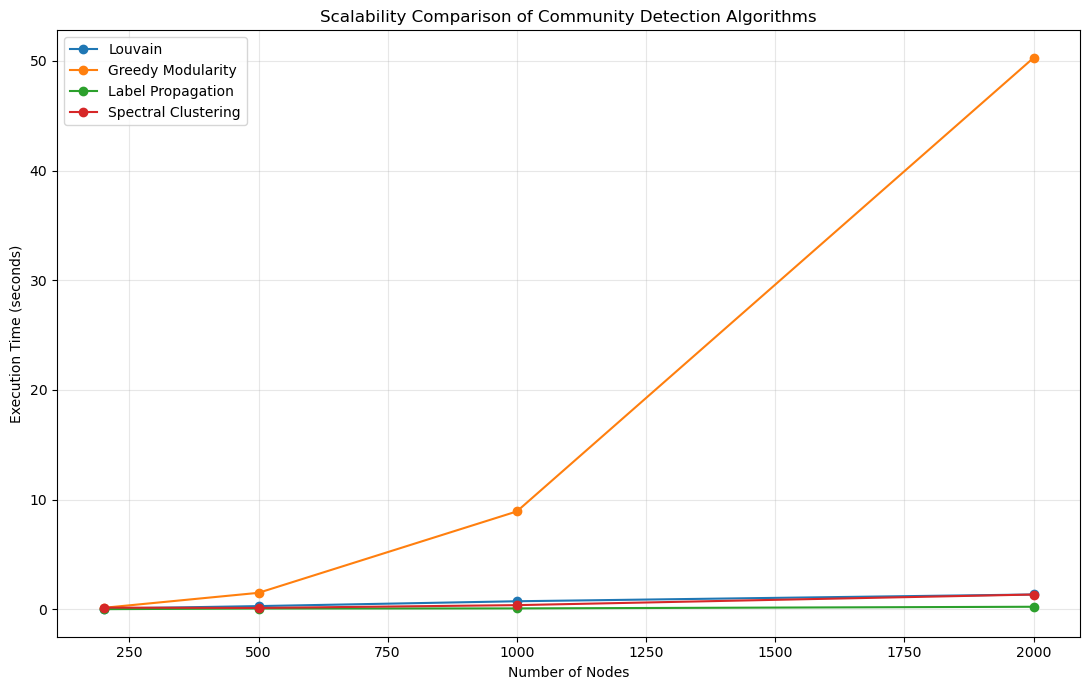

In [24]:
plt.figure(figsize=(11, 7))

for algorithm in scalability_df["Algorithm"].unique():

    data = scalability_df[
        scalability_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Nodes"],
        data["Runtime (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Number of Nodes")
plt.ylabel("Execution Time (seconds)")
plt.title("Scalability Comparison of Community Detection Algorithms")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
scalability_df.to_csv(
    "community_scalability_results.csv",
    index=False
)

print("Scalability results saved!")


Scalability results saved!


In [26]:
null_mean = np.mean(random_modularity)
null_std = np.std(random_modularity, ddof=1)

if null_std > 0:
    z_score = (
        observed_modularity - null_mean
    ) / null_std
else:
    z_score = np.nan

p_value = (
    1 + np.sum(
        np.array(random_modularity) >= observed_modularity
    )
) / (len(random_modularity) + 1)

significance_df = pd.DataFrame([{
    "Observed Modularity": observed_modularity,
    "Random Mean": null_mean,
    "Random Standard Deviation": null_std,
    "Z-score": z_score,
    "Empirical P-value": p_value
}])

display(significance_df.round(4))

NameError: name 'random_modularity' is not defined

In [27]:
import numpy as np
import networkx as nx
import pandas as pd
import community as community_louvain

random_modularity = []

observed_communities = results["Louvain"]

observed_modularity = nx.community.modularity(
    G,
    observed_communities
)

for trial in range(20):

    random_graph = G.copy()

    try:
        nx.double_edge_swap(
            random_graph,
            nswap=100,
            max_tries=5000,
            seed=trial + 42
        )

    except nx.NetworkXAlgorithmError:
        print(f"Trial {trial + 1} skipped")
        continue

    random_partition = community_louvain.best_partition(
        random_graph,
        random_state=trial + 42
    )

    random_communities = [
        {
            node for node, label in random_partition.items()
            if label == community
        }
        for community in sorted(set(random_partition.values()))
    ]

    modularity = nx.community.modularity(
        random_graph,
        random_communities
    )

    random_modularity.append(modularity)

print("Randomization completed!")
print("Successful trials:", len(random_modularity))
print("Observed modularity:", round(observed_modularity, 4))
print("Random modularity values:", random_modularity)

Randomization completed!
Successful trials: 20
Observed modularity: 0.4439
Random modularity values: [0.32703213610586007, 0.3253112439956867, 0.3423936631944445, 0.34736142977901224, 0.2955522861023087, 0.34542936288088644, 0.3008624763705104, 0.3033889422657, 0.32158611900794043, 0.32439608496459804, 0.3151117283171317, 0.3126936983471074, 0.3266186200378072, 0.3159556786703601, 0.29118075801749266, 0.2968965883728345, 0.3274702037677816, 0.35324968140378393, 0.3580498866213152, 0.3196814025827128]


In [28]:
null_mean = np.mean(random_modularity)
null_std = np.std(random_modularity, ddof=1)

if null_std > 0:
    z_score = (observed_modularity - null_mean) / null_std
else:
    z_score = np.nan

p_value = (
    1 + np.sum(
        np.array(random_modularity) >= observed_modularity
    )
) / (len(random_modularity) + 1)

significance_df = pd.DataFrame([{
    "Observed Modularity": observed_modularity,
    "Random Mean": null_mean,
    "Random Standard Deviation": null_std,
    "Z-score": z_score,
    "Empirical P-value": p_value
}])

display(significance_df.round(4))

,Observed Modularity,Random Mean,Random Standard Deviation,Z-score,Empirical P-value
0,0.4439,0.3225,0.0195,6.2243,0.0476


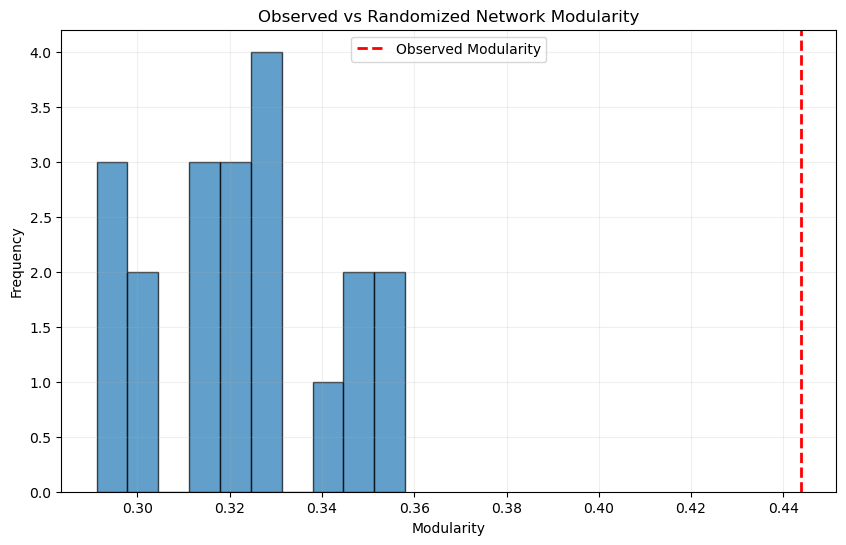

In [29]:
plt.figure(figsize=(10, 6))

plt.hist(
    random_modularity,
    bins=10,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    observed_modularity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Observed Modularity"
)

plt.xlabel("Modularity")
plt.ylabel("Frequency")
plt.title("Observed vs Randomized Network Modularity")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [30]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [34]:
import os

print("Checking Desktop locations...\n")

paths = [
    os.path.join(os.path.expanduser("~"), "Desktop"),
    os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop"),
    os.path.join(os.environ.get("OneDrive", ""), "Desktop")
]

for path in paths:
    if path and os.path.isdir(path):
        print("EXISTS:", path)
    else:
        print("NOT FOUND:", path)
        

Checking Desktop locations...

EXISTS: C:\Users\PALLAVI\Desktop
EXISTS: C:\Users\PALLAVI\OneDrive\Desktop
EXISTS: C:\Users\PALLAVI\OneDrive\Desktop


In [35]:
import os

desktop = os.path.join(
    os.environ["USERPROFILE"],
    "OneDrive",
    "Desktop"
)

if not os.path.isdir(desktop):
    raise FileNotFoundError(
        "OneDrive Desktop not found. Check Step 1 output."
    )

project_folder = os.path.join(
    desktop,
    "Community_Detection_Project"
)

results_folder = os.path.join(
    project_folder,
    "results"
)

os.makedirs(results_folder, exist_ok=True)

print("PROJECT CREATED:")
print(project_folder)

PROJECT CREATED:
C:\Users\PALLAVI\OneDrive\Desktop\Community_Detection_Project


In [36]:
output_files = {
    "algorithm_comparison.csv": comparison_df,
    "robustness_results.csv": robustness_df,
    "hub_bridge_analysis.csv": node_analysis,
    "scalability_results.csv": scalability_df,
    "significance_results.csv": significance_df
}

for filename, dataframe in output_files.items():

    path = os.path.join(results_folder, filename)

    dataframe.to_csv(path, index=False)

    print("SAVED:", filename)

print("\nAll result files saved!")

SAVED: algorithm_comparison.csv
SAVED: robustness_results.csv
SAVED: hub_bridge_analysis.csv
SAVED: scalability_results.csv
SAVED: significance_results.csv

All result files saved!


COMMUNITY DETECTION LIVE DEMONSTRATION
Selected Algorithm: Louvain
Number of Communities: 4
Modularity: 0.4439
NMI: 0.6
ARI: 0.5089
Execution Time: 0.004082 seconds


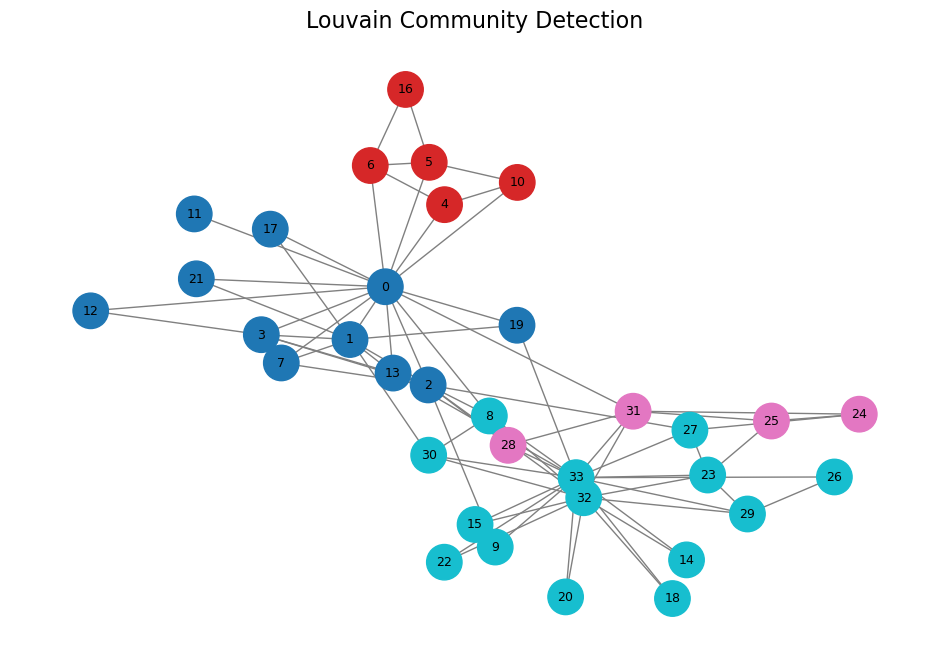

In [39]:
import time
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Select an algorithm here
selected_algorithm = "Louvain"

# Supported algorithms
available_algorithms = [
    "Louvain",
    "Greedy Modularity",
    "Label Propagation",
    "Spectral Clustering",
    "Girvan-Newman"
]

if selected_algorithm not in available_algorithms:
    raise ValueError("Invalid algorithm selected")

# Execute the selected algorithm
start_time = time.perf_counter()

detected_communities = detect_communities(
    G,
    selected_algorithm,
    target_k=len(results[selected_algorithm])
)

execution_time = time.perf_counter() - start_time

# Convert communities into labels
predicted_labels = np.zeros(
    G.number_of_nodes(),
    dtype=int
)

for community_id, community in enumerate(detected_communities):
    for node in community:
        predicted_labels[node] = community_id

# Calculate performance metrics
modularity = nx.community.modularity(
    G,
    detected_communities
)

nmi = normalized_mutual_info_score(
    ground_truth,
    predicted_labels
)

ari = adjusted_rand_score(
    ground_truth,
    predicted_labels
)

# Display results
print("=" * 50)
print("COMMUNITY DETECTION LIVE DEMONSTRATION")
print("=" * 50)

print("Selected Algorithm:", selected_algorithm)
print("Number of Communities:", len(detected_communities))
print("Modularity:", round(modularity, 4))
print("NMI:", round(nmi, 4))
print("ARI:", round(ari, 4))
print("Execution Time:", round(execution_time, 6), "seconds")

# Visualize communities
pos = nx.spring_layout(G, seed=42)

node_colors = [
    predicted_labels[node]
    for node in G.nodes()
]

plt.figure(figsize=(12, 8))

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    cmap=plt.cm.tab10,
    node_size=650,
    edge_color="gray",
    with_labels=True,
    font_size=9
)

plt.title(
    f"{selected_algorithm} Community Detection",
    fontsize=16
)

plt.axis("off")
plt.show()

COMMUNITY DETECTION LIVE DEMONSTRATION
Selected Algorithm: Spectral Clustering
Number of Communities: 4
Modularity: 0.4449
NMI: 0.5878
ARI: 0.4646
Execution Time: 0.036225 seconds


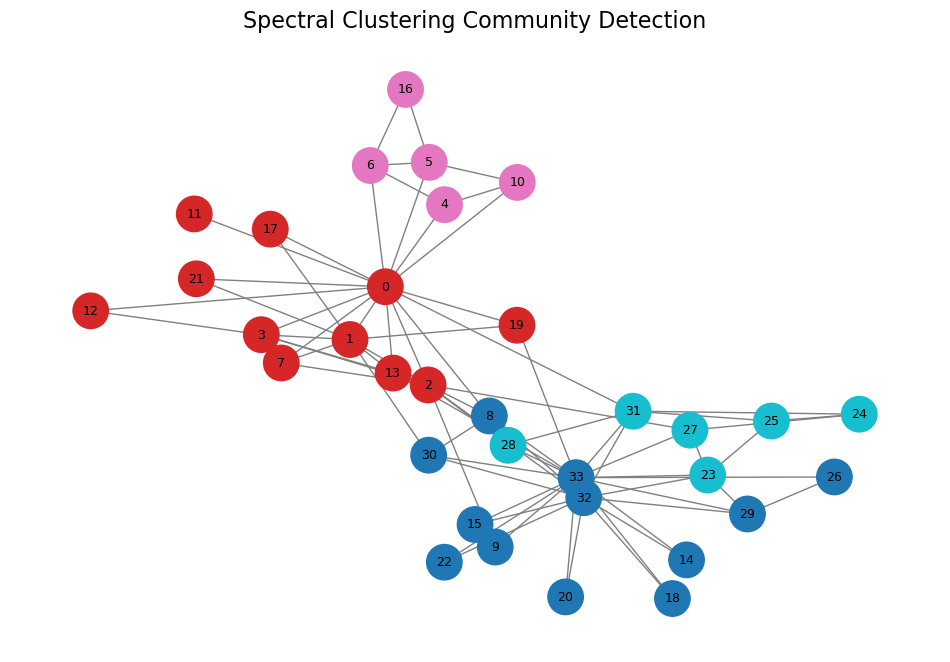

In [40]:
import time
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Select an algorithm here
selected_algorithm = "Spectral Clustering"

# Supported algorithms
available_algorithms = [
    "Louvain",
    "Greedy Modularity",
    "Label Propagation",
    "Spectral Clustering",
    "Girvan-Newman"
]

if selected_algorithm not in available_algorithms:
    raise ValueError("Invalid algorithm selected")

# Execute the selected algorithm
start_time = time.perf_counter()

detected_communities = detect_communities(
    G,
    selected_algorithm,
    target_k=len(results[selected_algorithm])
)

execution_time = time.perf_counter() - start_time

# Convert communities into labels
predicted_labels = np.zeros(
    G.number_of_nodes(),
    dtype=int
)

for community_id, community in enumerate(detected_communities):
    for node in community:
        predicted_labels[node] = community_id

# Calculate performance metrics
modularity = nx.community.modularity(
    G,
    detected_communities
)

nmi = normalized_mutual_info_score(
    ground_truth,
    predicted_labels
)

ari = adjusted_rand_score(
    ground_truth,
    predicted_labels
)

# Display results
print("=" * 50)
print("COMMUNITY DETECTION LIVE DEMONSTRATION")
print("=" * 50)

print("Selected Algorithm:", selected_algorithm)
print("Number of Communities:", len(detected_communities))
print("Modularity:", round(modularity, 4))
print("NMI:", round(nmi, 4))
print("ARI:", round(ari, 4))
print("Execution Time:", round(execution_time, 6), "seconds")

# Visualize communities
pos = nx.spring_layout(G, seed=42)

node_colors = [
    predicted_labels[node]
    for node in G.nodes()
]

plt.figure(figsize=(12, 8))

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    cmap=plt.cm.tab10,
    node_size=650,
    edge_color="gray",
    with_labels=True,
    font_size=9
)

plt.title(
    f"{selected_algorithm} Community Detection",
    fontsize=16
)

plt.axis("off")
plt.show()

In [41]:
best_algorithm = "Louvain"

print("=" * 50)
print("FINAL ALGORITHM RECOMMENDATION")
print("=" * 50)

print("Selected Algorithm:", best_algorithm)
print("Reason: Best overall balance of quality,")
print("robustness, scalability and execution time.")

print("\nOther algorithms:")
print("Label Propagation - Fastest")
print("Spectral Clustering - Competitive quality")
print("Greedy Modularity - Strong ARI")
print("Girvan-Newman - Computationally expensive")

FINAL ALGORITHM RECOMMENDATION
Selected Algorithm: Louvain
Reason: Best overall balance of quality,
robustness, scalability and execution time.

Other algorithms:
Label Propagation - Fastest
Spectral Clustering - Competitive quality
Greedy Modularity - Strong ARI
Girvan-Newman - Computationally expensive
